# ¿Qué explica el salario de un programador dentro de su país? — 5 redes neuronales

Encuesta Stack Overflow 2020, dataset depurado por `limpieza_stackoverflow.py`.

**Objetivo.** Comparar todos los países a la vez es poco práctico: el país por sí solo
explica casi toda la diferencia de salario (un programador de Estados Unidos gana
muchas veces lo que uno de India) y tapa todo lo demás. Por eso se entrena **una red
neuronal por país**, que explica las diferencias de salario **entre programadores del
mismo país**, y después se comparan los resultados de las cinco redes.

**Qué países.** Los 5 con **más salarios válidos** después de la limpieza (fase 1): una
red necesita muchos ejemplos para aprender, y un país con pocos datos daría un resultado
que depende más de la suerte que del modelo. La elección la hace el código con esa regla,
no se fija a mano.

**Problema:** regresión supervisada. Cada red predice `log(salario anual en USD)` a partir
del perfil del programador y se evalúa con el **R²**: la proporción de la variación del
salario *dentro del país* que la red logra explicar.

> Antes de correrlo hay que generar el dataset limpio:
> `.venv/bin/python limpieza_stackoverflow.py`

In [1]:
import json
import os
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Hide TensorFlow C++ logs (INFO, WARNING and ERROR) such as the missing CUDA libraries.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEMILLA = 42
# Hide Python-side TensorFlow warnings such as tf.function retracing inside loops.
tf.get_logger().setLevel("ERROR")
# Fija la semilla de Python, NumPy y TensorFlow a la vez, y obliga a TensorFlow
# a usar operaciones deterministas: dos corridas dan exactamente las mismas redes.
tf.keras.utils.set_random_seed(SEMILLA)
tf.config.experimental.enable_op_determinism()

SALIDAS = Path("salidas")
MODELOS = SALIDAS / "modelos"
ARCHIVO_LIMPIO = SALIDAS / "stackoverflow_limpio.csv"
COLUMNA_PAIS = "Country"
COLUMNA_OBJETIVO = "ConvertedComp"
N_PAISES = 5
# Nombre en el dataset -> nombre para tablas y gráficas
NOMBRES_PAIS = {"United States": "Estados Unidos", "India": "India", "United Kingdom": "Reino Unido",
                "Germany": "Alemania", "Canada": "Canadá", "Brazil": "Brasil", "France": "Francia",
                "Netherlands": "Países Bajos", "Poland": "Polonia", "Australia": "Australia",
                "Spain": "España", "Italy": "Italia", "Russian Federation": "Rusia", "Sweden": "Suecia"}
PALETA = ["#4c72b0", "#dd8452", "#55a868", "#c44e52", "#8172b3"]
print("TensorFlow", tf.__version__)

I0000 00:00:1794104841.107825 1697959 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1794104842.876764 1697959 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.22.0-rc0


## Fase 1 · Filtrar el dataset y elegir los países

1. **Solo salarios reportados y mayores que 0.** El 45,5 % de las filas recibió la mediana
   del salario durante la limpieza porque no respondió esa pregunta; la columna
   `ConvertedComp_reportado` dice cuáles son reales. La red aprende `log(salario)` y
   `log(0)` no existe.
2. **Sin salarios atípicos** (regla de Tukey, abajo).
3. **Los 5 países con más salarios válidos.**
4. **Preguntas de respuesta múltiple a columnas 0/1.** El tipo de desarrollador, las
   plataformas, las bases de datos y los frameworks web vienen como texto separado por
   `;` (por ejemplo `"Developer, back-end;Developer, front-end"`). Igual que los lenguajes
   (`usa_*`), cada opción se vuelve una columna binaria.

In [2]:
df = pd.read_csv(ARCHIVO_LIMPIO, low_memory=False)
reportados = df[df["ConvertedComp_reportado"] & (df[COLUMNA_OBJETIVO] > 0)].copy()
reportados["log_salario"] = np.log(reportados[COLUMNA_OBJETIVO])
print(f"Dataset limpio:              {len(df):>6} filas")
print(f"Con salario reportado (> 0): {len(reportados):>6} filas")

Dataset limpio:               63803 filas
Con salario reportado (> 0):  34614 filas


### Salarios atípicos: la regla de Tukey

Algunas respuestas son imposibles: en Estados Unidos **260 personas** reportaron
exactamente 2.000.000 USD, que es el tope de la encuesta, y más del 5 % supera los
890.000 USD. Lo más probable es que hayan escrito un salario mensual como si fuera anual
o se hayan equivocado de moneda. En el otro extremo hay salarios de 100 USD al año.
Esas filas no describen a ningún programador real y le enseñan ruido a la red.

Se usa la **regla de Tukey** (la misma de los bigotes de un diagrama de caja), aplicada
**dentro de cada país** y sobre `log(salario)`: se descarta lo que queda a más de
1,5 rangos intercuartílicos (IQR) por fuera de los cuartiles,

`[Q1 − 1,5·IQR ,  Q3 + 1,5·IQR]`.

Se aplica por país porque lo que es un salario atípico en India es normal en Estados
Unidos.

Después se cuentan los salarios válidos de cada país y se eligen los 5 con más datos
(sin contar `"Desconocido"`, que no es un país). La tabla muestra los 10 primeros.

In [3]:
def dentro_de_tukey(valores):
    q1, q3 = np.percentile(valores, [25, 75])
    iqr = q3 - q1
    return (valores >= q1 - 1.5 * iqr) & (valores <= q3 + 1.5 * iqr)


es_valido = reportados.groupby(COLUMNA_PAIS)["log_salario"].transform(
    lambda s: dentro_de_tukey(s.to_numpy())).astype(bool)
pais_de = reportados[COLUMNA_PAIS]
validos = reportados[es_valido]
ranking = pd.DataFrame({
    "salario reportado": pais_de.value_counts(),
    "atípicos quitados": (~es_valido).groupby(pais_de).sum(),
    "quedan": es_valido.groupby(pais_de).sum(),
    "salario mínimo aceptado (USD)": validos.groupby(COLUMNA_PAIS)[COLUMNA_OBJETIVO].min(),
    "salario máximo aceptado (USD)": validos.groupby(COLUMNA_PAIS)[COLUMNA_OBJETIVO].max(),
}).drop(index="Desconocido", errors="ignore")
ranking.insert(2, "% atípicos", ranking["atípicos quitados"] / ranking["salario reportado"])
ranking = ranking.sort_values("quedan", ascending=False).head(10)

PAISES = {p: NOMBRES_PAIS.get(p, p) for p in ranking.index[:N_PAISES]}
COLORES = dict(zip(PAISES, PALETA))
datos = validos[validos[COLUMNA_PAIS].isin(PAISES)].copy()

MULTIRESPUESTA = {"DevType": "dev_", "PlatformWorkedWith": "plat_",
                  "DatabaseWorkedWith": "db_", "WebframeWorkedWith": "web_"}
for columna, prefijo in MULTIRESPUESTA.items():
    datos = datos.join(datos[columna].fillna("").astype(str).str.get_dummies(sep=";").add_prefix(prefijo))
datos = datos.reset_index(drop=True)

print("Países elegidos:", ", ".join(PAISES.values()), f"· {len(datos)} filas en total")
(ranking.rename(index=lambda p: NOMBRES_PAIS.get(p, p)).style
 .format({c: "{:,.0f}" for c in ranking.columns if c != "% atípicos"} | {"% atípicos": "{:.1%}"})
 .apply(lambda fila: ["background-color: #cfe8cf" if fila.name in PAISES.values() else "" for _ in fila], axis=1))

Países elegidos: Estados Unidos, India, Reino Unido, Alemania, Canadá · 15552 filas en total


,salario reportado,atípicos quitados,% atípicos,quedan,salario mínimo aceptado (USD),salario máximo aceptado (USD)
Country,,,,,,
Estados Unidos,"8,123",679,8.4%,"7,444","31,800","421,000"
India,"2,624",109,4.2%,"2,515",768,"150,792"
Reino Unido,"2,580",277,10.7%,"2,303","14,219","341,244"
Alemania,"2,311",259,11.2%,"2,052","23,352","162,150"
Canadá,"1,342",104,7.7%,"1,238","23,800","196,641"
Brasil,"1,155",22,1.9%,"1,133","2,196","115,452"
Francia,"1,125",86,7.6%,"1,039","15,720","151,337"
Polonia,797,22,2.8%,775,"6,684","160,000"
Países Bajos,809,42,5.2%,767,"19,050","189,150"


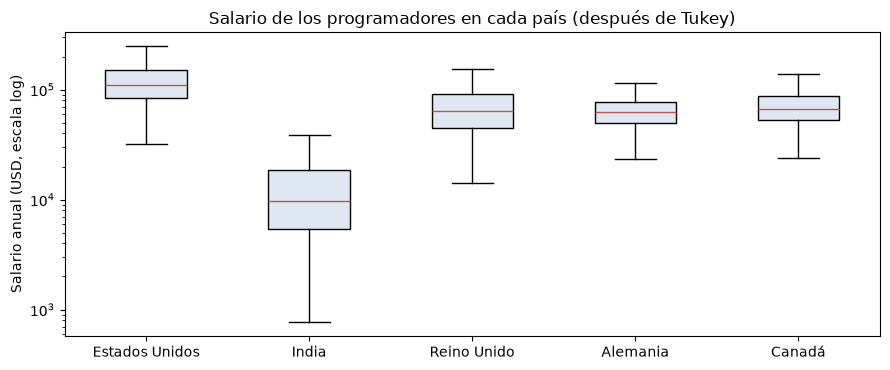

In [4]:
fig, eje = plt.subplots(figsize=(9, 3.8))
eje.boxplot([datos.loc[datos[COLUMNA_PAIS] == p, COLUMNA_OBJETIVO] for p in PAISES],
            tick_labels=list(PAISES.values()), showfliers=False, patch_artist=True,
            boxprops={"facecolor": "#dfe7f2"}, medianprops={"color": "#c44e52"})
eje.set_yscale("log")
eje.set_ylabel("Salario anual (USD, escala log)")
eje.set_title("Salario de los programadores en cada país (después de Tukey)")
plt.tight_layout()
plt.show()

La gráfica muestra por qué no tiene sentido mezclar los países: las cajas casi no se
tocan. La mediana de Estados Unidos es varias veces la de India. Dentro de
cada caja, en cambio, todavía hay mucha diferencia entre programadores, y eso es lo que
cada red tiene que explicar.

## Fase 2 · Partir los datos de cada país

Cada país se parte por separado, con la misma semilla:

| Conjunto | % del país | Para qué |
|---|---|---|
| Entrenamiento | 70 % | Ajustar los pesos de la red. |
| Validación | 10 % | Vigilar el sobreajuste y activar el *early stopping*. |
| Prueba | 20 % | Medir el resultado final **una sola vez**, con datos que la red nunca vio. |

La elección de variables (fase 3) y de arquitectura (fase 4) usa solo el 80 % de
entrenamiento + validación: el 20 % de prueba no se toca hasta la fase 6.

In [5]:
particiones = {}
for pais in PAISES:
    del_pais = datos[datos[COLUMNA_PAIS] == pais].reset_index(drop=True)
    resto, prueba = train_test_split(del_pais, test_size=0.20, random_state=SEMILLA)
    # 12,5 % del 80 % restante = 10 % del país
    entrenamiento, validacion = train_test_split(resto, test_size=0.125, random_state=SEMILLA)
    particiones[pais] = {"resto": resto, "entrenamiento": entrenamiento,
                         "validacion": validacion, "prueba": prueba}

pd.DataFrame({PAISES[p]: {c: len(particiones[p][c]) for c in ["entrenamiento", "validacion", "prueba"]}
              for p in PAISES}).T

,entrenamiento,validacion,prueba
Estados Unidos,5210,745,1489
India,1760,252,503
Reino Unido,1611,231,461
Alemania,1435,206,411
Canadá,866,124,248


Los países tienen tamaños muy distintos: Estados Unidos tiene miles de personas y el
quinto país, alrededor de mil. Para que la comparación no dependa de qué personas cayeron
por suerte en cada conjunto, además del R² de prueba se reporta el R² de **validación
cruzada de 5 pliegues**, que promedia cinco particiones distintas y es una medida más
estable.

## Fase 3 · ¿Qué variables aportan?

La primera versión del modelo usaba solo el lenguaje, la experiencia y el país. Sin el
país, el lenguaje y la experiencia explican muy poco de lo que gana un programador
dentro de su propio país. Se prueban otras preguntas de la encuesta que podrían explicar
el salario.

**Método.** Para cada país se mide el R² (validación cruzada de 5 pliegues, sobre el 80 %
de entrenamiento + validación) de un modelo base con **lenguajes + experiencia
profesional**, y después cuánto **sube** el R² al agregar cada variable candidata por
separado. Se usa una regresión lineal regularizada (Ridge) porque es rápida y estable;
la idea es medir cuánta información trae cada variable, no ajustar la red todavía.

Se queda con una variable si en promedio sube el R² al menos **0,005** (medio punto).

In [6]:
def con_prefijo(prefijo):
    return sorted(c for c in datos.columns if c.startswith(prefijo))

COLUMNAS_LENGUAJE = con_prefijo("usa_")
NUMERICAS = {"YearsCodePro", "Age", "WorkWeekHrs", "YearsCode"}
PREFIJOS_BINARIOS = ("usa_",) + tuple(MULTIRESPUESTA.values())

GRUPOS_CANDIDATOS = {
    "Lenguajes": COLUMNAS_LENGUAJE,
    "Experiencia profesional": ["YearsCodePro"],
    "Tipo de desarrollador": con_prefijo("dev_"),
    "Plataformas": con_prefijo("plat_"),
    "Bases de datos": con_prefijo("db_"),
    "Frameworks web": con_prefijo("web_"),
    "Tamaño de la empresa": ["OrgSize"],
    "Tipo de empleo": ["Employment"],
    "Nivel de estudios": ["EdLevel"],
    "Carrera universitaria": ["UndergradMajor"],
    "Sistema operativo": ["OpSys"],
    "Edad": ["Age"],
    "Horas de trabajo por semana": ["WorkWeekHrs"],
    "Años programando en total": ["YearsCode"],
    "Satisfacción laboral": ["JobSat"],
    "Género": ["Gender"],
    "Etnia": ["Ethnicity_agrupado"],
}
BASE = ["Lenguajes", "Experiencia profesional"]


def columnas_de(grupos):
    return [c for g in grupos for c in GRUPOS_CANDIDATOS[g]]


def construir_preprocesador(columnas):
    binarias = [c for c in columnas if c.startswith(PREFIJOS_BINARIOS)]
    numericas = [c for c in columnas if c in NUMERICAS]
    categoricas = [c for c in columnas if c not in binarias and c not in numericas]
    return ColumnTransformer([
        ("binarias", "passthrough", binarias),
        ("numericas", StandardScaler(), numericas),
        # Las categorías con menos de 5 personas se juntan en una sola columna.
        ("categoricas", OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=False), categoricas),
    ])


def r2_cv_lineal(tabla, columnas):
    r2 = []
    for entr, val in KFold(5, shuffle=True, random_state=SEMILLA).split(tabla):
        pre = construir_preprocesador(columnas)
        X_entr = pre.fit_transform(tabla.iloc[entr][columnas])
        modelo = RidgeCV(alphas=np.logspace(-1, 3, 9)).fit(X_entr, tabla.iloc[entr]["log_salario"])
        r2.append(r2_score(tabla.iloc[val]["log_salario"], modelo.predict(pre.transform(tabla.iloc[val][columnas]))))
    return float(np.mean(r2))


ganancia = {}
r2_base = {}
for pais in PAISES:
    resto = particiones[pais]["resto"]
    r2_base[pais] = r2_cv_lineal(resto, columnas_de(BASE))
    ganancia[PAISES[pais]] = {g: r2_cv_lineal(resto, columnas_de(BASE + [g])) - r2_base[pais]
                              for g in GRUPOS_CANDIDATOS if g not in BASE}
ganancia = pd.DataFrame(ganancia)
ganancia["media"] = ganancia.mean(axis=1)
ganancia = ganancia.sort_values("media", ascending=False)

UMBRAL = 0.005
SELECCIONADOS = BASE + ganancia.index[ganancia["media"] >= UMBRAL].tolist()
COLUMNAS = columnas_de(SELECCIONADOS)
print("R² del modelo base (lenguajes + experiencia):",
      {PAISES[p]: round(v, 3) for p, v in r2_base.items()})
ganancia.style.format("{:+.3f}").background_gradient(cmap="Greens", subset=["media"], vmin=0)

R² del modelo base (lenguajes + experiencia): {'Estados Unidos': 0.244, 'India': 0.278, 'Reino Unido': 0.207, 'Alemania': 0.239, 'Canadá': 0.267}


,Estados Unidos,India,Reino Unido,Alemania,Canadá,media
Tipo de desarrollador,+0.047,+0.014,+0.029,+0.048,+0.031,+0.034
Tamaño de la empresa,+0.031,+0.051,+0.017,+0.060,+0.008,+0.034
Plataformas,+0.035,+0.030,+0.019,+0.060,+0.023,+0.033
Sistema operativo,+0.023,+0.035,+0.020,+0.030,+0.019,+0.026
Bases de datos,+0.024,+0.021,+0.009,+0.019,+0.026,+0.020
Nivel de estudios,+0.010,+0.012,+0.006,+0.040,+0.029,+0.019
Tipo de empleo,+0.009,+0.001,+0.035,+0.035,+0.013,+0.018
Horas de trabajo por semana,+0.013,-0.001,+0.023,+0.011,+0.009,+0.011
Frameworks web,+0.007,+0.008,+0.008,+0.011,+0.016,+0.010
Carrera universitaria,+0.002,+0.001,+0.004,+0.019,+0.001,+0.005


In [7]:
print("Variables elegidas:")
for g in SELECCIONADOS:
    print(f"  - {g} ({len(GRUPOS_CANDIDATOS[g])} columna{'s' if len(GRUPOS_CANDIDATOS[g]) > 1 else ''})")
print("Descartadas:", ", ".join(g for g in GRUPOS_CANDIDATOS if g not in SELECCIONADOS))

Variables elegidas:
  - Lenguajes (25 columnas)
  - Experiencia profesional (1 columna)
  - Tipo de desarrollador (24 columnas)
  - Tamaño de la empresa (1 columna)
  - Plataformas (17 columnas)
  - Sistema operativo (1 columna)
  - Bases de datos (15 columnas)
  - Nivel de estudios (1 columna)
  - Tipo de empleo (1 columna)
  - Horas de trabajo por semana (1 columna)
  - Frameworks web (17 columnas)
  - Carrera universitaria (1 columna)
Descartadas: Edad, Años programando en total, Satisfacción laboral, Género, Etnia


**Lectura.** Lo que más explica el salario dentro de un país es **en qué trabaja** el
programador (plataformas, tipo de desarrollador, bases de datos, frameworks) y **dónde
trabaja** (tamaño de la empresa, tipo de empleo), además de su formación. El género, la
etnia y la satisfacción laboral no agregan información: se descartan, y así además la
calculadora no pregunta datos personales sensibles. Los años programando en total
tampoco suman, porque repiten lo que ya dice la experiencia profesional.

## Fase 4 · Elegir la arquitectura

Cada red es *feedforward*: cada neurona calcula una suma ponderada de sus entradas,
`z = w·x + b`, y la pasa por la activación ReLU, `max(0, z)`. Al apilar **varias capas
ocultas**, cada capa combina lo que encontró la anterior: la primera puede detectar, por
ejemplo, "desarrollador back-end en empresa grande", y las siguientes combinan esos
patrones. La salida es lineal porque predice un número cualquiera, el `log(salario)`.

Tres detalles del entrenamiento:

- **Objetivo estandarizado.** La red aprende `(log(salario) − media) / desviación` y una
  capa final `Rescaling` deshace la estandarización. Sin esto la red arranca prediciendo
  0 cuando la respuesta ronda 11 y el entrenamiento se vuelve inestable.
- **Regularización.** Con unas 140 entradas y pocos datos en algunos países, la red
  puede memorizar el conjunto de entrenamiento. *Dropout* (apaga al azar el 30 % de las
  neuronas en cada paso) y L2 (castiga los pesos grandes) lo evitan.
- ***Early stopping*.** Se detiene cuando el error de validación lleva 20 épocas sin
  mejorar y se queda con los mejores pesos.

Se usa una red de **5 capas ocultas (128, 64, 32, 16, 8)** con *dropout* solo después de
la 2.ª y la 5.ª capa, y L2 fuerte. Para tener referencia se compara con otras cinco
arquitecturas, todas con **al menos dos capas ocultas**, con validación
cruzada de 5 pliegues en cada país (sobre el 80 % de entrenamiento + validación). Como
referencia se incluye la regresión lineal Ridge con las mismas variables. Se usa **una
sola arquitectura para los cinco países**: así la comparación entre países es justa,
porque cambian los datos y no el modelo.

In [8]:
DROPOUT = 0.3
# (neuronas por capa, L2, capas ocultas seguidas de dropout)
CANDIDATAS = {
    "5 capas (128, 64, 32, 16, 8), dropout en 2.ª y 5.ª": ([128, 64, 32, 16, 8], 1e-2, (2, 5)),
    "5 capas (64, 32, 32, 16, 16), dropout en 2.ª y 5.ª": ([64, 32, 32, 16, 16], 1e-2, (2, 5)),
    "2 capas (64, 32)": ([64, 32], 1e-3, (1, 2)),
    "3 capas (64, 32, 16)": ([64, 32, 16], 1e-3, (1, 2, 3)),
    "3 capas (64, 32, 16), L2 fuerte": ([64, 32, 16], 1e-2, (1, 2, 3)),
    "3 capas (128, 64, 32)": ([128, 64, 32], 1e-3, (1, 2, 3)),
}


def construir_red(n_entradas, capas, l2, con_dropout, media, desviacion):
    regularizador = tf.keras.regularizers.l2(l2)
    ocultas = []
    for i, neuronas in enumerate(capas, start=1):
        ocultas.append(tf.keras.layers.Dense(neuronas, activation="relu", kernel_regularizer=regularizador,
                                             name=f"oculta_{i}"))
        if i in con_dropout:
            ocultas.append(tf.keras.layers.Dropout(DROPOUT, name=f"dropout_{i}"))
    return tf.keras.Sequential(
        [tf.keras.layers.Input(shape=(n_entradas,)), *ocultas,
         tf.keras.layers.Dense(1, activation="linear", name="salida"),
         tf.keras.layers.Rescaling(scale=desviacion, offset=media, name="log_salario")])


def entrenar(red, X_entr, y_entr, X_val, y_val):
    red.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="mse")
    return red.fit(
        X_entr, y_entr, validation_data=(X_val, y_val), epochs=300, batch_size=32, verbose=0,
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)])


def preparar(tabla_entr, *otras):
    pre = construir_preprocesador(COLUMNAS)
    X = [pre.fit_transform(tabla_entr[COLUMNAS]).astype("float32")]
    X += [pre.transform(t[COLUMNAS]).astype("float32") for t in otras]
    return pre, X


def r2_cv(resto):
    # R² de cada pliegue y residuos fuera de pliegue (personas que la red no vio).
    r2 = {n: [] for n in [*CANDIDATAS, "Regresión lineal (Ridge)"]}
    residuos = {n: [] for n in CANDIDATAS}
    for k, (idx_a, idx_b) in enumerate(KFold(5, shuffle=True, random_state=SEMILLA).split(resto)):
        entr, val = train_test_split(resto.iloc[idx_a], test_size=0.125, random_state=SEMILLA)
        evaluado = resto.iloc[idx_b]
        _, (X_entr, X_val, X_eval) = preparar(entr, val, evaluado)
        y_entr, y_val = entr["log_salario"].to_numpy(), val["log_salario"].to_numpy()
        lineal = RidgeCV(alphas=np.logspace(-1, 3, 9)).fit(X_entr, y_entr)
        r2["Regresión lineal (Ridge)"].append(r2_score(evaluado["log_salario"], lineal.predict(X_eval)))
        for nombre, (capas, l2, con_dropout) in CANDIDATAS.items():
            tf.keras.utils.set_random_seed(k)
            red = construir_red(X_entr.shape[1], capas, l2, con_dropout, y_entr.mean(), y_entr.std())
            entrenar(red, X_entr, y_entr, X_val, y_val)
            pred = red.predict(X_eval, verbose=0).ravel()
            r2[nombre].append(r2_score(evaluado["log_salario"], pred))
            residuos[nombre].append(evaluado["log_salario"].to_numpy() - pred)
    return r2, {n: np.concatenate(v) for n, v in residuos.items()}


cv, residuos_cv = {}, {}
for pais in PAISES:
    cv[pais], residuos_cv[pais] = r2_cv(particiones[pais]["resto"])
tabla_cv = pd.DataFrame({PAISES[p]: {n: np.mean(v) for n, v in cv[p].items()} for p in PAISES})
tabla_cv["media"] = tabla_cv.mean(axis=1)
# Arquitectura fijada: 5 capas ocultas con dropout en la 2.ª y la 5.ª. Las demás quedan como referencia.
ARQUITECTURA = next(iter(CANDIDATAS))
CAPAS, L2, CON_DROPOUT = CANDIDATAS[ARQUITECTURA]
print("Arquitectura usada:", ARQUITECTURA)
print("Mejor en promedio:", tabla_cv.drop(index="Regresión lineal (Ridge)")["media"].idxmax())
tabla_cv.style.format("{:.3f}").highlight_max(axis=0, color="#cfe8cf")

Arquitectura usada: 5 capas (128, 64, 32, 16, 8), dropout en 2.ª y 5.ª
Mejor en promedio: 3 capas (64, 32, 16), L2 fuerte


,Estados Unidos,India,Reino Unido,Alemania,Canadá,media
"5 capas (128, 64, 32, 16, 8), dropout en 2.ª y 5.ª",0.395,0.359,0.385,0.316,0.288,0.349
"5 capas (64, 32, 32, 16, 16), dropout en 2.ª y 5.ª",0.408,0.372,0.388,0.173,0.367,0.342
"2 capas (64, 32)",0.431,0.381,0.366,0.330,0.350,0.371
"3 capas (64, 32, 16)",0.420,0.376,0.348,0.349,0.335,0.366
"3 capas (64, 32, 16), L2 fuerte",0.414,0.382,0.399,0.407,0.383,0.397
"3 capas (128, 64, 32)",0.422,0.357,0.342,0.343,0.367,0.366
Regresión lineal (Ridge),0.388,0.378,0.325,0.418,0.369,0.376


La red de **5 capas** queda en 0,349 de R² promedio: por debajo de la de 3 capas con L2
fuerte (0,397) y de la regresión lineal (0,376). Tiene unos 29.000 pesos para entre 870 y
5.200 personas por país y solo dos capas con *dropout*, así que se sobreajusta más, sobre
todo en Alemania y Canadá, donde además el R² varía mucho entre pliegues (±0,15). La
versión angosta de 5 capas mejora en cuatro países, pero en Alemania deja de aprender y
predice casi siempre el mismo salario. Con estos datos, **más capas no dan más R²**: la
información de la encuesta pone el techo, no la profundidad de la red.

## Fase 5 · Entrenar las 5 redes

Una red por país, todas con la misma arquitectura de 5 capas ocultas. Cada una tiene su propio preprocesador:
la media y la desviación de la experiencia, la edad y las horas se calculan con los
datos de entrenamiento **de ese país**.

In [9]:
modelos, preprocesadores, historiales, conjuntos = {}, {}, {}, {}
for pais in PAISES:
    p = particiones[pais]
    pre, (X_entr, X_val, X_prueba) = preparar(p["entrenamiento"], p["validacion"], p["prueba"])
    y_entr, y_val = p["entrenamiento"]["log_salario"].to_numpy(), p["validacion"]["log_salario"].to_numpy()
    tf.keras.utils.set_random_seed(SEMILLA)
    red = construir_red(X_entr.shape[1], CAPAS, L2, CON_DROPOUT, y_entr.mean(), y_entr.std())
    historiales[pais] = entrenar(red, X_entr, y_entr, X_val, y_val)
    modelos[pais], preprocesadores[pais] = red, pre
    conjuntos[pais] = {"X_entr": X_entr, "X_val": X_val, "X_prueba": X_prueba, "y_entr": y_entr, "y_val": y_val,
                       "y_prueba": p["prueba"]["log_salario"].to_numpy()}
    print(f"{PAISES[pais]:<15} {X_entr.shape[1]} entradas · "
          f"{len(historiales[pais].history['loss'])} épocas · "
          f"mejor época {int(np.argmin(historiales[pais].history['val_loss'])) + 1}")

modelos[next(iter(PAISES))].summary()

Estados Unidos  142 entradas · 152 épocas · mejor época 132


India           136 entradas · 37 épocas · mejor época 17


Reino Unido     141 entradas · 53 épocas · mejor época 33


Alemania        140 entradas · 223 épocas · mejor época 203


Canadá          139 entradas · 118 épocas · mejor época 98


Model: "sequential_150"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 128)            │        18,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_3 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_4 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_5 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ log_salario (Rescaling)         │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 87,941 (343.52 KB)

 Trainable params: 29,313 (114.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 58,628 (229.02 KB)

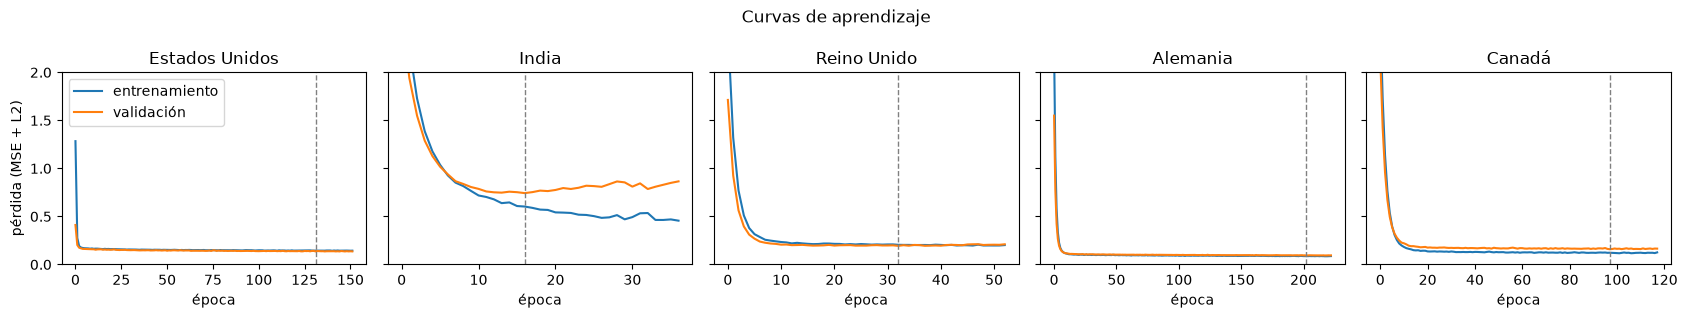

In [10]:
fig, ejes = plt.subplots(1, 5, figsize=(17, 3.2), sharey=True)
for eje, pais in zip(ejes, PAISES):
    h = historiales[pais].history
    eje.plot(h["loss"], label="entrenamiento")
    eje.plot(h["val_loss"], label="validación")
    eje.axvline(int(np.argmin(h["val_loss"])), color="grey", linestyle="--", linewidth=1)
    eje.set_title(PAISES[pais])
    eje.set_xlabel("época")
ejes[0].set_ylabel("pérdida (MSE + L2)")
ejes[0].set_ylim(0, 2)
ejes[0].legend()
plt.suptitle("Curvas de aprendizaje")
plt.tight_layout()
plt.show()

## Fase 6 · Evaluar cada red

Es regresión, así que **no** aplican Accuracy ni F1-Score (son de clasificación). Se usan:

- **R² sobre `log(salario)`:** qué proporción de la variación del salario *dentro del país*
  explica la red (0 = nada, 1 = todo). Es la métrica principal.
- **MAE en USD:** cuántos dólares se equivoca la red en promedio, después de deshacer el
  logaritmo.
- **Modelo base:** siempre predice la mediana del país. Si la red no le gana, no aprendió
  nada útil.

Se reporta el R² del conjunto de prueba y el de validación cruzada (fase 4), que es más
estable cuando el país tiene pocos datos.

In [11]:
def predecir(pais, tabla):
    X = preprocesadores[pais].transform(tabla[COLUMNAS]).astype("float32")
    return modelos[pais].predict(X, verbose=0).ravel()


filas = []
for pais in PAISES:
    c = conjuntos[pais]
    pred = modelos[pais].predict(c["X_prueba"], verbose=0).ravel()
    lineal = RidgeCV(alphas=np.logspace(-1, 3, 9)).fit(c["X_entr"], c["y_entr"])
    base = np.full_like(c["y_prueba"], np.median(c["y_entr"]))
    real_usd = np.exp(c["y_prueba"])
    filas.append({
        "país": PAISES[pais],
        "personas (entren.)": len(c["y_entr"]),
        "R² prueba · red": r2_score(c["y_prueba"], pred),
        "R² validación cruzada · red": np.mean(cv[pais][ARQUITECTURA]),
        "± (desv. entre pliegues)": np.std(cv[pais][ARQUITECTURA]),
        "R² prueba · lineal": r2_score(c["y_prueba"], lineal.predict(c["X_prueba"])),
        "R² prueba · modelo base": r2_score(c["y_prueba"], base),
        "MAE red (USD)": mean_absolute_error(real_usd, np.exp(pred)),
        "MAE modelo base (USD)": mean_absolute_error(real_usd, np.exp(base)),
        "salario mediano (USD)": np.exp(np.median(c["y_entr"])),
    })
resultados = pd.DataFrame(filas).set_index("país")
resultados.style.format({c: "{:.3f}" for c in resultados.columns if "R²" in c or "±" in c}
                        | {c: "{:,.0f}" for c in resultados.columns if "USD" in c})

,personas (entren.),R² prueba · red,R² validación cruzada · red,± (desv. entre pliegues),R² prueba · lineal,R² prueba · modelo base,MAE red (USD),MAE modelo base (USD),salario mediano (USD)
país,,,,,,,,,
Estados Unidos,5210,0.406,0.395,0.016,0.383,-0.003,"32,417","42,654","110,000"
India,1760,0.439,0.359,0.054,0.448,-0.002,"7,282","10,195","10,052"
Reino Unido,1611,0.302,0.385,0.058,0.233,-0.001,"25,570","31,247","64,630"
Alemania,1435,0.399,0.316,0.160,0.413,-0.005,"13,350","17,636","62,697"
Canadá,866,0.394,0.288,0.151,0.358,-0.002,"14,720","19,524","65,799"


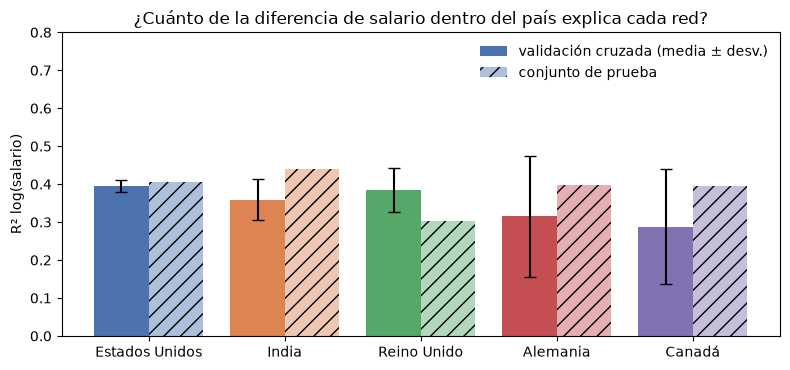

Estados Unidos  explica el 40% de la variación · se equivoca 32,417 USD en promedio (24% menos que la mediana)
India           explica el 36% de la variación · se equivoca 7,282 USD en promedio (29% menos que la mediana)
Reino Unido     explica el 38% de la variación · se equivoca 25,570 USD en promedio (18% menos que la mediana)
Alemania        explica el 32% de la variación · se equivoca 13,350 USD en promedio (24% menos que la mediana)
Canadá          explica el 29% de la variación · se equivoca 14,720 USD en promedio (25% menos que la mediana)


In [12]:
fig, eje = plt.subplots(figsize=(8, 3.8))
posiciones = np.arange(len(PAISES))
eje.bar(posiciones - 0.2, resultados["R² validación cruzada · red"], 0.4,
        yerr=resultados["± (desv. entre pliegues)"], capsize=4,
        color=[COLORES[p] for p in PAISES], label="validación cruzada (media ± desv.)")
eje.bar(posiciones + 0.2, resultados["R² prueba · red"], 0.4, color=[COLORES[p] for p in PAISES],
        alpha=0.45, hatch="//", label="conjunto de prueba")
eje.set_xticks(posiciones, resultados.index)
eje.set_ylabel("R² log(salario)")
eje.set_ylim(0, 0.8)
eje.set_title("¿Cuánto de la diferencia de salario dentro del país explica cada red?")
eje.legend(frameon=False)
plt.tight_layout()
plt.show()

for pais in PAISES:
    fila = resultados.loc[PAISES[pais]]
    mejora = 1 - fila["MAE red (USD)"] / fila["MAE modelo base (USD)"]
    print(f"{PAISES[pais]:<15} explica el {fila['R² validación cruzada · red']:.0%} de la variación · "
          f"se equivoca {fila['MAE red (USD)']:,.0f} USD en promedio ({mejora:.0%} menos que la mediana)")

**Cómo leer estos números frente al modelo anterior.** La primera versión (una sola red
para todos los países) tenía un R² de validación de 0,50, pero ese número incluía las
diferencias **entre** países, que son las más fáciles de predecir: basta con saber el
país para acertar buena parte del salario. Aquí cada red explica solo las diferencias
**dentro** de su país, que son mucho más difíciles. Por eso los dos números no se comparan
directamente. La comparación justa es contra el modelo con solo lenguajes y experiencia
dentro de cada país (fase 3): las variables nuevas y quitar los salarios imposibles son lo
que sube el R².

## Fase 7 · Comparar los 5 países

Con una red por país se puede responder: **¿qué pesa más en el salario de un
programador en cada país?**

### ¿Qué variables usa cada red? Importancia por permutación

Para medir cuánto depende una red de una variable se **desordena** esa variable en el
conjunto de prueba (se mezclan sus valores entre las personas, rompiendo su relación con
el salario) y se mide cuánto **cae el R²**. Si la red casi no la usa, el R² no cambia; si
depende mucho de ella, cae bastante. Las variables de varias columnas (por ejemplo, todas
las plataformas) se desordenan juntas. Se repite 20 veces y se promedia.

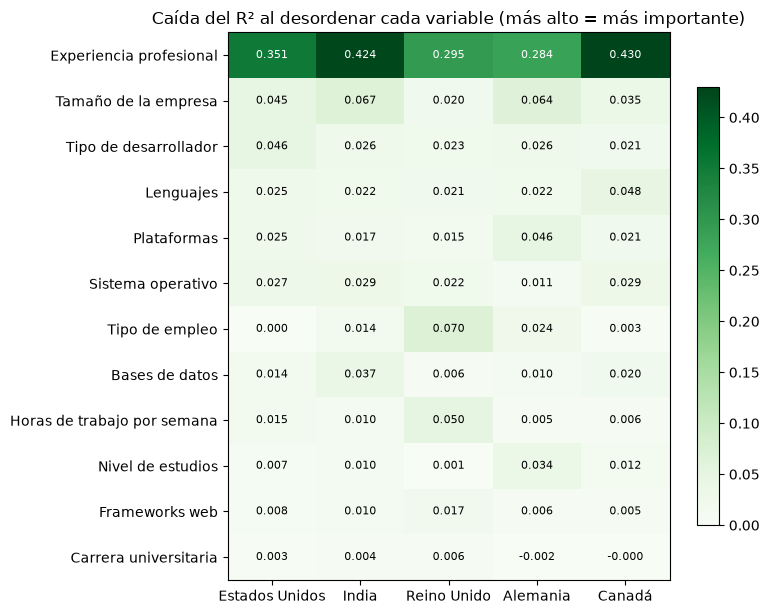

In [13]:
def importancia_permutacion(pais, repeticiones=20):
    prueba = particiones[pais]["prueba"]
    y = prueba["log_salario"].to_numpy()
    r2_original = r2_score(y, predecir(pais, prueba))
    azar = np.random.default_rng(SEMILLA)
    caida = {}
    for grupo in SELECCIONADOS:
        columnas = GRUPOS_CANDIDATOS[grupo]
        caidas = []
        for _ in range(repeticiones):
            desordenada = prueba.copy()
            desordenada[columnas] = prueba[columnas].to_numpy()[azar.permutation(len(prueba))]
            caidas.append(r2_original - r2_score(y, predecir(pais, desordenada)))
        caida[grupo] = np.mean(caidas)
    return caida


importancia = pd.DataFrame({PAISES[p]: importancia_permutacion(p) for p in PAISES})
importancia = importancia.loc[importancia.mean(axis=1).sort_values(ascending=False).index]

fig, eje = plt.subplots(figsize=(8, 0.42 * len(importancia) + 1.2))
mapa = eje.imshow(importancia.clip(lower=0), cmap="Greens", aspect="auto")
eje.set_xticks(range(len(importancia.columns)), importancia.columns)
eje.set_yticks(range(len(importancia)), importancia.index)
for i in range(len(importancia)):
    for j in range(len(importancia.columns)):
        valor = importancia.iat[i, j]
        eje.text(j, i, f"{valor:.3f}", ha="center", va="center", fontsize=8,
                 color="white" if valor > importancia.to_numpy().max() * 0.6 else "black")
eje.set_title("Caída del R² al desordenar cada variable (más alto = más importante)")
fig.colorbar(mapa, ax=eje, shrink=0.8)
plt.tight_layout()
plt.show()

### ¿Cuánto paga la experiencia en cada país?

Para cada país se toma a todas las personas del conjunto de prueba, se les cambia **solo
los años de experiencia** (de 0 a 20) dejando todo lo demás igual, y se mira la mediana del
salario que predice la red. Es una **gráfica de dependencia parcial**: aísla el efecto de
la experiencia según lo aprendió cada red.

A la derecha, cada curva se divide por su valor con 1 año de experiencia, para comparar
el **crecimiento** y no el nivel: un 2,0 significa que la red espera que el salario se
duplique.

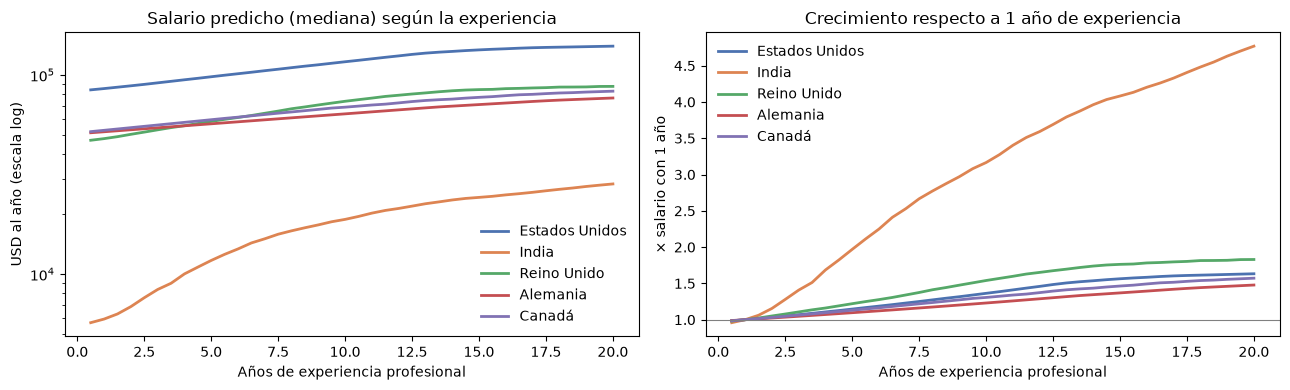

Salario con 10 años / salario con 1 año:
Estados Unidos    1.36
India             3.17
Reino Unido       1.54
Alemania          1.23
Canadá            1.31


In [14]:
ANIOS = np.arange(0.5, 20.5, 0.5)
curvas = {}
for pais in PAISES:
    prueba = particiones[pais]["prueba"].copy()
    medianas = []
    for anios in ANIOS:
        prueba["YearsCodePro"] = anios
        medianas.append(np.median(np.exp(predecir(pais, prueba))))
    curvas[pais] = np.array(medianas)

fig, (izq, der) = plt.subplots(1, 2, figsize=(13, 4))
for pais in PAISES:
    izq.plot(ANIOS, curvas[pais], color=COLORES[pais], linewidth=2, label=PAISES[pais])
    der.plot(ANIOS, curvas[pais] / curvas[pais][ANIOS == 1.0][0], color=COLORES[pais], linewidth=2,
             label=PAISES[pais])
izq.set_yscale("log")
izq.set_title("Salario predicho (mediana) según la experiencia")
izq.set_ylabel("USD al año (escala log)")
der.axhline(1, color="grey", linewidth=0.8)
der.set_title("Crecimiento respecto a 1 año de experiencia")
der.set_ylabel("× salario con 1 año")
for eje in (izq, der):
    eje.set_xlabel("Años de experiencia profesional")
    eje.legend(frameon=False)
plt.tight_layout()
plt.show()

crecimiento = pd.Series({PAISES[p]: curvas[p][ANIOS == 10.0][0] / curvas[p][ANIOS == 1.0][0] for p in PAISES})
print("Salario con 10 años / salario con 1 año:")
print(crecimiento.round(2).to_string())

### Resumen de la comparación

La tabla junta, por país, el resultado de la red y la variable que más pesa.

In [15]:
comparacion = pd.DataFrame({
    "R² (validación cruzada)": resultados["R² validación cruzada · red"],
    "salario mediano (USD)": resultados["salario mediano (USD)"],
    "× salario de 1 a 10 años": crecimiento,
    "variable más importante": importancia.idxmax(),
    "segunda": importancia.apply(lambda col: col.sort_values(ascending=False).index[1]),
})
comparacion.style.format({"R² (validación cruzada)": "{:.3f}", "salario mediano (USD)": "{:,.0f}",
                          "× salario de 1 a 10 años": "{:.2f}"})

,R² (validación cruzada),salario mediano (USD),× salario de 1 a 10 años,variable más importante,segunda
Estados Unidos,0.395,"110,000",1.36,Experiencia profesional,Tipo de desarrollador
India,0.359,"10,052",3.17,Experiencia profesional,Tamaño de la empresa
Reino Unido,0.385,"64,630",1.54,Experiencia profesional,Tipo de empleo
Alemania,0.316,"62,697",1.23,Experiencia profesional,Tamaño de la empresa
Canadá,0.288,"65,799",1.31,Experiencia profesional,Lenguajes


**Cuidado al comparar:** en los países con menos datos el conjunto de prueba tiene
unas 250 personas, así que la importancia de cada variable y la curva de experiencia
tienen más margen de error. Las conclusiones más firmes salen de los países más grandes.

## Fase 8 · ¿Qué tan lejos queda la estimación? Los residuos

El residuo es `log(salario real) − log(salario predicho)`. Si se distribuye como una
normal centrada en 0 con desviación σ, el **68 %** de las personas con ese perfil gana
entre `estimación × e^(−σ)` y `estimación × e^(+σ)`. La calculadora muestra ese rango.

Se usa una **σ robusta**, `1,4826 × MAD` (mediana de las desviaciones absolutas), que no
se deja inflar por unos pocos salarios extremos. σ se calcula con los **residuos fuera de
pliegue** de la validación cruzada (fase 4): cada persona del 80 % fue predicha una vez
por una red que no la vio, así que hay muchos más residuos que en la validación sola
(importante en los países con menos datos). Los residuos de entrenamiento **no** sirven: la red ya conoce
esas personas y su error sale artificialmente pequeño. Después se comprueba con
**prueba**: si cerca del 68 % de las personas de prueba cae dentro de ±1σ, el rango es
honesto.

In [16]:
def sigma_robusta(residuos):
    return float(1.4826 * np.median(np.abs(residuos - np.median(residuos))))


SIGMAS, filas = {}, []
for pais in PAISES:
    c = conjuntos[pais]
    SIGMAS[pais] = sigma_robusta(residuos_cv[pais][ARQUITECTURA])
    residuos_prueba = c["y_prueba"] - modelos[pais].predict(c["X_prueba"], verbose=0).ravel()
    filas.append({"país": PAISES[pais], "σ robusta": SIGMAS[pais],
                  "rango del 68 %": f"×{np.exp(-SIGMAS[pais]):.2f} a ×{np.exp(SIGMAS[pais]):.2f}",
                  "en prueba dentro de ±1σ": np.mean(np.abs(residuos_prueba) <= SIGMAS[pais])})
pd.DataFrame(filas).set_index("país").style.format({"σ robusta": "{:.3f}", "en prueba dentro de ±1σ": "{:.1%}"})

,σ robusta,rango del 68 %,en prueba dentro de ±1σ
país,,,
Estados Unidos,0.304,×0.74 a ×1.36,66.4%
India,0.602,×0.55 a ×1.83,71.8%
Reino Unido,0.340,×0.71 a ×1.41,63.8%
Alemania,0.244,×0.78 a ×1.28,67.2%
Canadá,0.303,×0.74 a ×1.35,73.0%


## Fase 9 · Guardar las 5 redes

La calculadora carga estos archivos de `salidas/`:

- `modelos/<país>.keras` y `modelos/<país>_preprocesador.joblib`: cada red y su
  preprocesador ya ajustado.
- `calculadora_opciones.json`: las variables elegidas, las opciones de cada pregunta por
  país, las métricas y σ de cada red.
- `salarios_referencia.csv`: los salarios reales de los 5 países, para mostrar junto a
  cada estimación lo que gana de verdad la gente con un perfil parecido.

In [17]:
MODELOS.mkdir(parents=True, exist_ok=True)


def archivo_de(pais):
    return pais.lower().replace(" ", "_")


def tipo_de(grupo):
    columnas = GRUPOS_CANDIDATOS[grupo]
    if columnas[0].startswith(PREFIJOS_BINARIOS):
        return "multiple"
    return "numerica" if columnas[0] in NUMERICAS else "categorica"


grupos = {}
for grupo in SELECCIONADOS:
    columnas = GRUPOS_CANDIDATOS[grupo]
    grupos[grupo] = {"tipo": tipo_de(grupo), "columnas": columnas}
    if grupos[grupo]["tipo"] == "multiple":
        grupos[grupo]["prefijo"] = columnas[0].split("_", 1)[0] + "_"

paises = {}
for pais in PAISES:
    modelos[pais].save(MODELOS / f"{archivo_de(pais)}.keras")
    joblib.dump(preprocesadores[pais], MODELOS / f"{archivo_de(pais)}_preprocesador.joblib")
    entrenamiento = particiones[pais]["entrenamiento"]
    paises[pais] = {
        "nombre": PAISES[pais],
        "archivo": archivo_de(pais),
        "metricas": {k: float(v) for k, v in resultados.loc[PAISES[pais]].items()},
        "sigma_residuos_log": SIGMAS[pais],
        "categorias": {g["columnas"][0]: entrenamiento[g["columnas"][0]].value_counts().index.tolist()
                       for g in grupos.values() if g["tipo"] == "categorica"},
        "numericas": {g["columnas"][0]: {"min": float(entrenamiento[g["columnas"][0]].min()),
                                         "max": float(entrenamiento[g["columnas"][0]].max()),
                                         "mediana": float(entrenamiento[g["columnas"][0]].median())}
                      for g in grupos.values() if g["tipo"] == "numerica"},
    }

opciones = {"arquitectura": ARQUITECTURA, "capas": CAPAS, "dropout_en": list(CON_DROPOUT), "grupos": grupos, "paises": paises,
            "importancia": importancia.to_dict()}
(SALIDAS / "calculadora_opciones.json").write_text(json.dumps(opciones, ensure_ascii=False, indent=2))
datos[[COLUMNA_PAIS, COLUMNA_OBJETIVO] + COLUMNAS].to_csv(SALIDAS / "salarios_referencia.csv", index=False)
print("Guardado en", SALIDAS.resolve())

Guardado en /home/danso/orca/projects/Personal/Estadistica3/salidas
